# Random Forest & Bagging: 

**Goal:** Predict log price with ensembles of decision trees. Both methods train many trees on random samples of cars and average their predictions, which reduces the variance of a single tree.

- **Bagging** (bootstrap aggregating) trains each tree on a random sample of cars. Every split can consider all features.
- **Random forest** does the same, and also limits each split to a random subset of features. This makes the trees less correlated, so averaging them helps more.

**Setup:** Same cleaned data, 80/20 split (`random_state=42`), and 5-fold CV as the other notebooks. Categorical features are one-hot encoded, and numeric features pass through unchanged, since trees don't need scaling.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load the cleaned data saved from the KNN notebook's cleaning steps
df = pd.read_csv('../data/cardekho_clean.csv')
df['log_price'] = np.log(df['selling_price'])

num_cols = ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
cat_cols = ['brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']
X = df[num_cols + cat_cols]
y = df['log_price']

# Same split and CV as the KNN notebook so results are comparable
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

LUXURY = ['Land Rover', 'Jaguar', 'Mercedes-Benz', 'Audi', 'BMW']

def evaluate(pred_log, name):
    rmse = np.sqrt(mean_squared_error(y_test, pred_log))
    r2 = r2_score(y_test, pred_log)
    mae = mean_absolute_error(np.exp(y_test), np.exp(pred_log))
    print(f"{name}: test RMSE (log) {rmse:.4f} | R2 {r2:.4f} | MAE Rs {mae:,.0f}")
    return {'model': name, 'test_rmse_log': round(rmse, 4), 'test_r2': round(r2, 4), 'test_mae_rs': round(mae)}

def segment_report(pred_log):
    d = pd.DataFrame({
        'actual': np.exp(y_test.values),
        'pred': np.exp(pred_log),
        'brand': X_test['brand'].values,
    })
    d['pct_error'] = np.abs(d['pred'] - d['actual']) / d['actual']
    d['segment'] = pd.qcut(d['actual'], 4, labels=['Q1 cheapest', 'Q2', 'Q3', 'Q4 priciest'])
    return d

def print_segments(pred_log):
    d = segment_report(pred_log)
    print(d.groupby('segment', observed=True)['pct_error'].mean().round(3))
    print(d[d['brand'].isin(LUXURY)].groupby('brand')['pct_error'].agg(['size', 'mean']).round(3))

def original_feature(name):
    # Maps one-hot names like 'cat__brand_Maruti' back to 'brand'
    name = name.split('__', 1)[1]
    for col in cat_cols + num_cols:
        if name == col or name.startswith(col + '_'):
            return col
    return name

print(X_train.shape, X_test.shape)

(12184, 11) (3046, 11)


## 1. Tune the forest

The grid is kept small because each combination fits 5 folds of 300 trees. Our first run chose depth 20, `max_features=0.5`, and `min_samples_leaf=1`. Those values sit at the edges of the grid, so a wider search is a possible next step.

In [2]:
from sklearn.ensemble import RandomForestRegressor

rf_prep = ColumnTransformer(
    [('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)],
    remainder='passthrough'
)
rf_pipe = Pipeline([
    ('prep', rf_prep),
    ('rf', RandomForestRegressor(random_state=42, n_jobs=-1)),
])
rf_param_grid = {
    'rf__n_estimators': [300],
    'rf__max_depth': [None, 20],
    'rf__min_samples_leaf': [1, 5],
    'rf__max_features': [0.3, 0.5],
}
grid_rf = GridSearchCV(rf_pipe, rf_param_grid, cv=cv,
                       scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_rf.fit(X_train, y_train)
print("best params:", grid_rf.best_params_)
print("best CV RMSE (log):", round(-grid_rf.best_score_, 4))

best params: {'rf__max_depth': 20, 'rf__max_features': 0.5, 'rf__min_samples_leaf': 1, 'rf__n_estimators': 300}
best CV RMSE (log): 0.1719


## 2. Evaluate on the test set

In [3]:
best_rf = grid_rf.best_estimator_
pred_rf = best_rf.predict(X_test)
rf_result = evaluate(pred_rf, 'Random forest')

Random forest: test RMSE (log) 0.1744 | R2 0.9332 | MAE Rs 91,155


## 3. Feature importances

The forest shares importance across correlated features. For example, engine size and max power carry much of the same signal, so the forest gives engine more weight than a single tree does.

max_power            0.416
vehicle_age          0.204
engine               0.167
transmission_type    0.065
km_driven            0.045
model                0.038
brand                0.019
mileage              0.019
fuel_type            0.018
seller_type          0.006
seats                0.004
dtype: float64


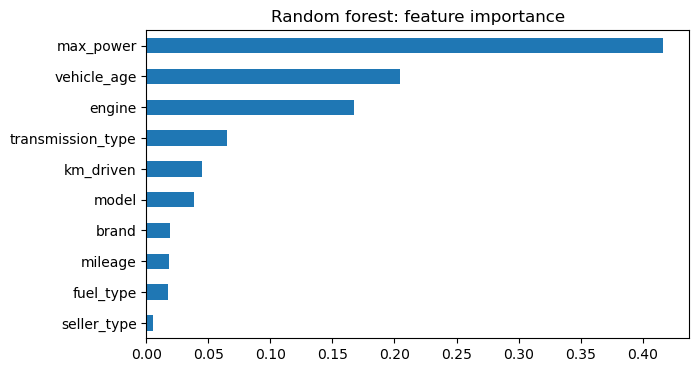

In [4]:
rf_names = best_rf.named_steps['prep'].get_feature_names_out()
rf_imp = pd.Series(best_rf.named_steps['rf'].feature_importances_, index=rf_names)
rf_grouped = rf_imp.groupby([original_feature(n) for n in rf_names]).sum().sort_values(ascending=False)
print(rf_grouped.round(3))

rf_grouped.head(10).sort_values().plot(kind='barh', figsize=(7, 4), title='Random forest: feature importance')
plt.show()

## 4. Error by price segment and luxury brand

In [5]:
print_segments(pred_rf)

segment
Q1 cheapest    0.181
Q2             0.120
Q3             0.102
Q4 priciest    0.119
Name: pct_error, dtype: float64
               size   mean
brand                     
Audi             33  0.134
BMW              78  0.139
Jaguar           14  0.170
Land Rover       11  0.231
Mercedes-Benz    58  0.159


## 5. Bagging (bootstrap aggregating)

Bagging trains many decision trees, each on a bootstrap sample (a random sample of cars drawn with replacement), and averages their predictions. Unlike a random forest, bagging lets every split consider all the features. The only source of randomness is the sample of cars.

Comparing bagging with the random forest shows how much of the forest's gain comes from sampling rows alone and how much comes from also sampling features at each split.

In [6]:
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor

bag_prep = ColumnTransformer(
    [('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)],
    remainder='passthrough'
)
bag_pipe = Pipeline([
    ('prep', bag_prep),
    ('bag', BaggingRegressor(estimator=DecisionTreeRegressor(random_state=42),
                             random_state=42, n_jobs=-1)),
])
bag_param_grid = {
    'bag__n_estimators': [300],
    'bag__estimator__max_depth': [None, 20],
    'bag__estimator__min_samples_leaf': [1, 5],
    'bag__max_samples': [0.8, 1.0],
}
grid_bag = GridSearchCV(bag_pipe, bag_param_grid, cv=cv,
                        scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_bag.fit(X_train, y_train)
print("best params:", grid_bag.best_params_)
print("best CV RMSE (log):", round(-grid_bag.best_score_, 4))

best params: {'bag__estimator__max_depth': 20, 'bag__estimator__min_samples_leaf': 1, 'bag__max_samples': 0.8, 'bag__n_estimators': 300}
best CV RMSE (log): 0.1729


### 5a. Evaluate bagging on the test set

In [7]:
best_bag = grid_bag.best_estimator_
pred_bag = best_bag.predict(X_test)
bag_result = evaluate(pred_bag, 'Bagging (trees)')

pd.DataFrame([rf_result, bag_result])
print_segments(pred_bag)

Bagging (trees): test RMSE (log) 0.1755 | R2 0.9325 | MAE Rs 92,895
segment
Q1 cheapest    0.180
Q2             0.122
Q3             0.102
Q4 priciest    0.122
Name: pct_error, dtype: float64
               size   mean
brand                     
Audi             33  0.126
BMW              78  0.142
Jaguar           14  0.177
Land Rover       11  0.249
Mercedes-Benz    58  0.170


### Bagging vs Random Forest: 

| Model | CV RMSE | Test RMSE | R² | MAE |
|---|---|---|---|---|
| Random forest | 0.1719 | 0.1744 | 0.9332 | ₹91,155 |
| Bagging (trees) | 0.1729 | 0.1755 | 0.9325 | ₹92,895 |

- **Bagging is nearly as good as the forest.** Its CV and test RMSE are about 0.001 higher, and its R² is about 0.001 lower. Most of the forest's advantage comes from averaging many trees trained on random samples of cars.
- **The forest's extra feature sampling adds a small gain.** It is better on BMW, Jaguar, Land Rover, and Mercedes-Benz. Bagging is better on Audi (12.6% vs 13.4%).
- **The price quartiles are nearly identical.** Bagging is 18.0%, 12.2%, 10.2%, and 12.2%. The forest is 18.1%, 12.0%, 10.2%, and 11.9%.
- **The differences are small.** A gap of about 0.001 in RMSE on 3,046 test cars is unlikely to matter much, so both models are good candidates for the final comparison.